# The spam filter with scikit-learn

In [A naive Bayes classifier by hand](naive_bayes_by_hand.ipynb), the classifier was a few lines of Python, and scikit-learn's `MultinomialNB` turned out to be the same model. From here on the library does the arithmetic, and the filter is treated like any other model: other ways of turning text into numbers, a comparison with a different classifier, a threshold chosen for what each mistake costs, and a look at the messages it gets wrong. The workflow is the one of [Supervised learning](../../README.md): candidates compared by cross-validation on the training messages, and the test set used once.

## The messages

The same messages, without repetitions, and the same split as before. The target is 1 for spam and 0 for ham, so that "positive" means spam in every measure:

In [ ]:
from sklearn.model_selection import train_test_split

from sms_spam import load_sms_spam

messages = load_sms_spam().drop_duplicates(subset="message")
train, test = train_test_split(messages, test_size=0.2, stratify=messages["label"], random_state=42)
X_train, X_test = train["message"], test["message"]
y_train, y_test = (train["label"] == "spam").astype(int), (test["label"] == "spam").astype(int)
len(X_train), len(X_test)

(4136, 1035)

## Ways of turning text into numbers

A classifier needs numbers, and there is more than one way to get them from text:

- **Counts** (`CountVectorizer`): how many times each word appears, as in [A naive Bayes classifier by hand](naive_bayes_by_hand.ipynb).
- **Presence** (`binary=True`): whether each word appears, 1 or 0, however many times.
- **TF-IDF** (`TfidfVectorizer`): the count, scaled down for words that appear in many messages. A word that appears everywhere (*the*, *you*) says little about any message, and gets a small weight.
- **Pairs of words** (`ngram_range=(1, 2)`): each pair of consecutive words counts as one more feature, so that "free entry" is something other than "free" and "entry".

Naive Bayes with each of them, and [logistic regression](../../algorithms/linear-models/logistic_regression.ipynb) on TF-IDF, the usual strong baseline for text, compared by 5-fold cross-validation on the training messages:

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

WORDS = r"[a-z0-9£]+"
candidates = {
    "naive Bayes, counts": make_pipeline(CountVectorizer(token_pattern=WORDS), MultinomialNB()),
    "naive Bayes, presence": make_pipeline(CountVectorizer(token_pattern=WORDS, binary=True), MultinomialNB()),
    "naive Bayes, TF-IDF": make_pipeline(TfidfVectorizer(token_pattern=WORDS), MultinomialNB()),
    "naive Bayes, words and pairs": make_pipeline(CountVectorizer(token_pattern=WORDS, ngram_range=(1, 2)), MultinomialNB()),
    "logistic regression, TF-IDF": make_pipeline(TfidfVectorizer(token_pattern=WORDS), LogisticRegression(C=10, max_iter=1000)),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cross_validated = pd.DataFrame({
    name: pd.DataFrame(cross_validate(model, X_train, y_train, cv=folds, scoring=["precision", "recall", "f1"])).mean()
    for name, model in candidates.items()
}).T[["test_precision", "test_recall", "test_f1", "fit_time"]]
cross_validated.round(3)

,test_precision,test_recall,test_f1,fit_time
"naive Bayes, counts",0.973,0.912,0.941,0.019
"naive Bayes, presence",0.981,0.898,0.937,0.019
"naive Bayes, TF-IDF",1.000,0.584,0.736,0.020
"naive Bayes, words and pairs",0.989,0.895,0.939,0.056
"logistic regression, TF-IDF",0.987,0.887,0.934,0.030


Naive Bayes on word counts has the best F1 (0.94), but presence, pairs of words and the logistic regression are within a few thousandths of it, which is about what different folds alone produce. One candidate is clearly worse: naive Bayes on TF-IDF catches only 58% of the spam. TF-IDF turns a message into a few small fractional weights, which add up to far less than its number of words, so the smoothing, one extra occurrence of every word of the vocabulary, outweighs the evidence, and the class prior, which favours ham, decides. With a much smaller `alpha` it does about as well as counts: `alpha` is a setting to tune, left here at its default. Any of them trains in a few hundredths of a second. The simplest, naive Bayes on counts, is chosen.

## What each mistake costs

The two errors of a spam filter are not equal. Spam that gets through costs a second of attention; a legitimate message sent to the spam folder may never be read: a job offer, a message from a doctor. So the filter should flag a message only when it is very sure, which means a high threshold on the probability of spam ([the threshold](../../evaluation/classification_metrics.ipynb#the-threshold)). The threshold is a setting, so it is chosen on the training messages, with cross-validated probabilities:

In [ ]:
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import cross_val_predict

chosen_name = "naive Bayes, counts"
chosen_model = candidates[chosen_name]
training_probabilities = cross_val_predict(chosen_model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]


def at_threshold(threshold):
    flagged = training_probabilities >= threshold
    return {
        "ham sent to spam": int((flagged & (y_train == 0)).sum()),
        "spam let through": int((~flagged & (y_train == 1)).sum()),
        "precision": precision_score(y_train, flagged),
        "recall": recall_score(y_train, flagged),
    }


pd.DataFrame({threshold: at_threshold(threshold) for threshold in (0.5, 0.7, 0.9, 0.97, 0.99)}).T.rename_axis("threshold").round(3)

,ham sent to spam,spam let through,precision,recall
threshold,,,,
0.50,13.0,46.0,0.973,0.912
0.70,8.0,53.0,0.983,0.898
0.90,3.0,63.0,0.994,0.879
0.97,1.0,74.0,0.998,0.858
0.99,0.0,81.0,1.000,0.845


At the default 0.5, 13 of the roughly 3,600 training ham messages would end in the spam folder. Raising the threshold trades them for spam let through: at 0.99, not one ham message is lost in cross-validation, and 81 of the roughly 520 spam messages pass, a recall of 0.85. For a spam folder that nobody checks, that is the better trade, and 0.99 is chosen.

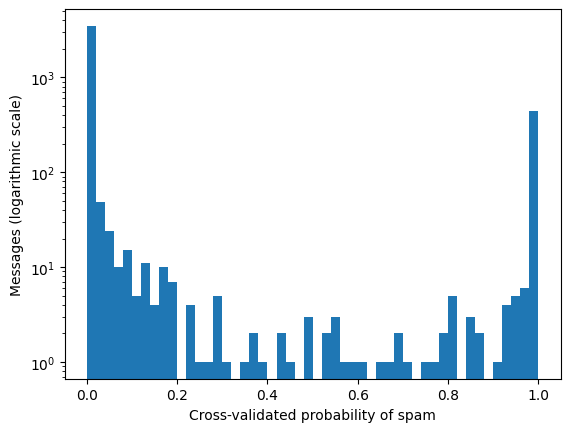

In [ ]:
import matplotlib.pyplot as plt

plt.hist(training_probabilities, bins=50)
plt.yscale("log")
plt.xlabel("Cross-validated probability of spam")
plt.ylabel("Messages (logarithmic scale)")
plt.show()

Almost every message gets a probability close to 0 or close to 1; the vertical axis is logarithmic, so the bars in the middle are a few messages each, against thousands near 0 and hundreds near 1. This is the overconfidence of the naive assumption, which counts every word as separate evidence: the scores pile up at the ends, and some spam scores 0.000, as the mistakes below show. The threshold still works, because it only uses the *order* of the scores, but a score has to be read as a position in that order, not as a probability.

## Testing once

In [ ]:
from sklearn.metrics import confusion_matrix

threshold = 0.99
chosen_model.fit(X_train, y_train)
test_probabilities = chosen_model.predict_proba(X_test)[:, 1]
test_flagged = (test_probabilities >= threshold).astype(int)
pd.DataFrame(confusion_matrix(y_test, test_flagged), index=["true ham", "true spam"], columns=["predicted ham", "predicted spam"])

,predicted ham,predicted spam
true ham,904,0
true spam,18,113


On the 1,035 test messages, the filter sends no ham to the spam folder and lets 18 of the 131 spam messages through: a recall of 0.86 at a precision of 1.00, close to what cross-validation predicted.

## What the filter gets wrong

In [ ]:
pd.set_option("display.max_colwidth", 160)
mistakes = test.assign(probability_of_spam=test_probabilities.round(3))[test_flagged != y_test]
explicit = mistakes["message"].str.contains(r"sex|xxx|babe|busty|nasty|cumin", case=False)
shown = mistakes.loc[~explicit].assign(message=lambda rows: rows["message"].str.replace("SHIT", "S***"))
shown[["label", "probability_of_spam", "message"]].sort_values("probability_of_spam")

,label,probability_of_spam,message
4144,spam,0.000,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)"
4213,spam,0.006,Missed call alert. These numbers called but left no message. 07008009200
5542,spam,0.018,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A S***. BAILIFF DUE IN DAYS. I O £250 3 WANT £800
3530,spam,0.024,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!"
5451,spam,0.308,"Latest News! Police station toilet stolen, cops have nothing to go on!"
3981,spam,0.557,ringtoneking 84484
788,spam,0.605,Ever thought about living a good life with a perfect partner? Just txt back NAME and AGE to join the mobile community. (100p/SMS)
672,spam,0.635,"SMS. ac sun0819 posts HELLO:""You seem cool, wanted to say hi. HI!!!"" Stop? Send STOP to 62468"
2770,spam,0.777,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner
2269,spam,0.885,88066 FROM 88066 LOST 3POUND HELP


Every mistake is spam that got through: 18 messages, of which 8, sexually explicit adverts mostly written like personal messages, are left out of the table above. The rest are short and almost wordless ("ringtoneking 84484"), or belong to a kind of spam that is rare in the training messages, such as a quiz about *The Simpsons* or a Burger King football promotion. A few labels are debatable, too: the complaint in capitals about a phone bill reads more like an angry customer than like spam. A model learns the labels it is given, mistakes included.

## The words that weigh most

A naive Bayes model can be read word by word. The difference between a word's log-probability in spam and in ham is how much each occurrence moves the score towards one class; the words that move it most, both ways, in a naive Bayes model on word counts:

In [ ]:
import numpy as np

reader = make_pipeline(CountVectorizer(token_pattern=WORDS), MultinomialNB()).fit(X_train, y_train)
vocabulary = reader[0].get_feature_names_out()
log_ratio = reader[1].feature_log_prob_[1] - reader[1].feature_log_prob_[0]
order = np.argsort(log_ratio)
pd.DataFrame({
    "towards ham": vocabulary[order[:15]],
    "towards spam": vocabulary[order[::-1][:15]],
})

,towards ham,towards spam
0,gt,claim
1,lt,prize
2,he,150p
3,lor,nokia
4,da,tone
5,she,co
6,later,www
7,really,18
8,but,guaranteed
9,doing,£1


The spam side holds what anyone would expect: "claim", "prize", "guaranteed", "awarded", prices ("150p", "£1", "£1000"), "ringtone", "www". The ham side holds a warning. "gt" and "lt" are pieces of `&lt;#&gt;` and `&lt;URL&gt;`, placeholders that the source of the ham messages put where it removed numbers and links: more than two hundred ham messages contain them, and not one spam message. "lor" and "da", colloquial forms of the English spoken in Singapore, also appear only in ham. The collection's documentation explains why: most of its ham comes from a corpus of messages written by students in Singapore, and most of its spam from a British web forum.

So part of what the filter has learned is *where each message was collected*, which a filter on a real phone would never see. A test set drawn from the same collection can't reveal that, because it shares the same origin. Only reading the data and its documentation can, and only messages from the place where the filter will be used can measure how much it matters.

## Where naive Bayes stands today

Naive Bayes made spam filtering work at scale: Paul Graham's essay *A Plan for Spam* (2002) made it popular, and filters such as SpamAssassin still include a Bayesian component. Its strengths are those these notebooks showed: it learns by counting, so it trains in an instant, needs little data and can be read word by word; and since counts can simply be added to, it can be updated message by message (`partial_fit`). Its weaknesses too: the independence assumption, and probabilities too extreme to be read as probabilities.

On text classification today it is a baseline, the first model to try and the one to beat. A linear model on TF-IDF features, like the logistic regression above, is usually as good or better at little extra cost. On harder problems, where meaning depends on the order and context of the words, models that read the whole text, such as the transformers behind language models, do much better, at a far higher cost: they are a subject of their own.